(sec-5-1)=
# 5.1 Representing Periodic Signals with Sinusoids

An ECG beat has rounded waves and a sharp QRS complex, so it does not look much like a sine wave. Fourier series give us a way to build a repeating shape by adding sine and cosine waves at different frequencies. I find it easier to understand this as a gradual reconstruction: start with a few smooth components, then add the detail.

We will first use signals that repeat exactly so that the mathematics is clear. Then we will relate the results to physiological waveforms. Real heartbeats vary from beat to beat, so a periodic model is an approximation whose limits we should keep in mind.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-5-1-1)=
## 5.1.1 Fourier, Heat and Vibrating Strings

The idea of building functions from sines is older than Fourier. In the 1750s Daniel Bernoulli argued that the motion of a vibrating string is a superposition of its sinusoidal modes, and Euler, who disagreed, used trigonometric sums himself in astronomy. The decisive step came from a different physical problem. In 1807 Joseph Fourier presented to the Paris Institute a memoir on how heat spreads through a solid body. He found that a temperature profile shaped like a single sine decays in time without changing its shape, so he proposed to write *any* initial temperature profile, even one with corners and jumps, as a sum of sines and let each term decay at its own rate. Lagrange and others objected that a sum of smooth functions could not possibly represent a discontinuous one. The work was eventually published in full as *Théorie analytique de la chaleur* in 1822 {cite:p}`fourier1822`, and it took several more decades, starting with Dirichlet's convergence proof in 1829, to settle precisely when Fourier's claim holds. We return to that question in [Section 5.3](03_convergence_gibbs.ipynb).

Fourier's reasoning carries over directly to our setting. Heat conduction is a linear process, and a sine is a shape that the process preserves. Linear time-invariant systems behave the same way toward sinusoids in time. So the same decomposition that solved the heat equation also tells us what a filter does to an ECG.

Before any formulas, it helps to see the idea at work. The figure below adds three sinusoids at 1, 3 and 5 Hz with carefully chosen amplitudes. Their sum, with a fundamental period of 1 s, already looks like a rough square wave. Adding more terms of the same pattern would sharpen the corners further; the amplitudes we use here are derived in Section 5.1.5.

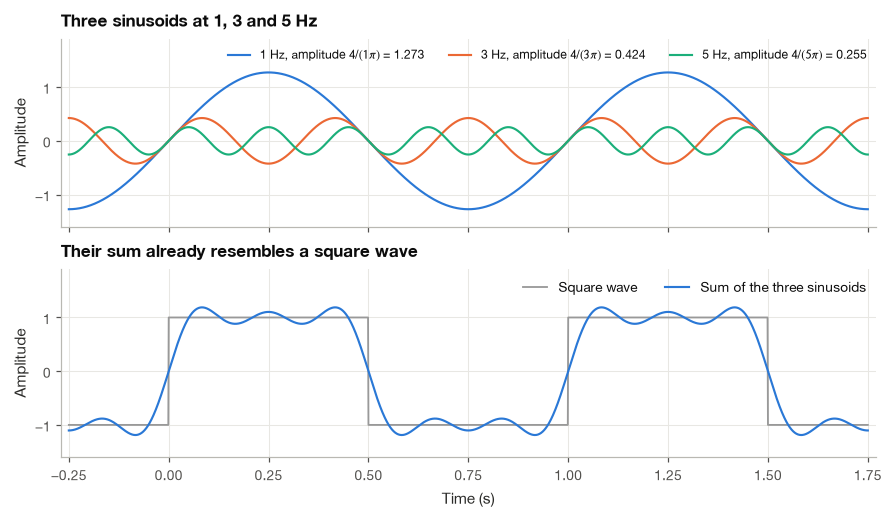

In [2]:
T = 1.0                                   # period (s)
w0 = 2 * np.pi / T                        # fundamental angular frequency (rad/s)
t = np.linspace(-0.25, 1.75, 2001)
harmonics = {n: 4 / (n * np.pi) * np.sin(n * w0 * t) for n in (1, 3, 5)}
square = np.where((t % T) < T / 2, 1.0, -1.0)

fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
for k, (n, h) in enumerate(harmonics.items()):
    axes[0].plot(t, h, color=C[k], label=f"{n} Hz, amplitude $4/({n}\\pi)$ = {4 / (n * np.pi):.3f}")
axes[0].set(ylabel="Amplitude", title="Three sinusoids at 1, 3 and 5 Hz")
axes[0].legend(loc="upper right", ncols=3, fontsize=8)
axes[0].set_ylim(-1.6, 1.9)

axes[1].plot(t, square, color="0.6", lw=1.2, label="Square wave")
axes[1].plot(t, sum(harmonics.values()), color=C[0], label="Sum of the three sinusoids")
axes[1].set(xlabel="Time (s)", ylabel="Amplitude", title="Their sum already resembles a square wave")
axes[1].legend(loc="upper right", ncols=2)
axes[1].set_ylim(-1.6, 1.9)
plt.show()

(sec-5-1-2)=
## 5.1.2 The Trigonometric Fourier Series

A signal $x(t)$ is **periodic** with period $T > 0$ if $x(t + T) = x(t)$ for every $t$. The smallest such $T$ is the **fundamental period**, its reciprocal $f_0 = 1/T$ is the **fundamental frequency** in hertz, and $\omega_0 = 2\pi f_0 = 2\pi/T$ is the fundamental angular frequency in radians per second. For an ECG at 72 beats per minute, $T = 0.833$ s, $f_0 = 1.2$ Hz and $\omega_0 = 7.54$ rad/s.

A sinusoid $\cos(n\omega_0 t)$ with integer $n \ge 1$ completes exactly $n$ cycles in every interval of length $T$, so it is periodic with period $T$ as well (its own fundamental period is $T/n$, but $T$ is also a period). The same holds for $\sin(n\omega_0 t)$. Any sum of such terms therefore repeats every $T$ seconds. Fourier's claim is the converse: a periodic signal with period $T$ can be written as

(eq-5-1)=
\begin{equation*}
x(t) = a_0 + \sum_{n=1}^{\infty}\Big[a_n\cos(n\omega_0 t) + b_n\sin(n\omega_0 t)\Big]. \tag{5.1}
\end{equation*}

Read the expression in layers. The constant $a_0$ gives the average level. For each positive integer $n$, the bracket adds a cosine and a sine at $n$ times the fundamental angular frequency $\omega_0=2\pi/T$. The coefficients $a_n$ and $b_n$ say how much of those two components to use. Keeping only the first few values of $n$ gives an approximation that we can plot before considering the infinite series.

This is the **trigonometric Fourier series**. The term with $n = 1$ is the **fundamental**, and the terms with $n = 2, 3, \ldots$ are the second, third, ... **harmonics**, at frequencies $2f_0, 3f_0, \ldots$. The constant $a_0$ is the **DC component**. Equation [(5.1)](#eq-5-1) contains no frequencies between the harmonics: a signal that repeats every $T$ seconds is built only from oscillations that also repeat every $T$ seconds.

Two questions follow immediately. Given $x(t)$, how do we find the numbers $a_0$, $a_n$ and $b_n$? And in what sense does the infinite sum actually equal $x(t)$? This section answers the first question. The second is subtle enough to deserve [Section 5.3](03_convergence_gibbs.ipynb).

```{note}
Many textbooks write the constant term as $a_0/2$ instead of $a_0$. That choice makes the formula for $a_0$ look like the formula for $a_n$ with $n = 0$, at the price of a factor of two everywhere else. I keep $a_0$ equal to the mean value of the signal, which is easier to interpret physically (for an ECG it is simply the baseline offset). Always check which convention a reference uses before comparing numbers.
```

(sec-5-1-3)=
## 5.1.3 Orthogonality of Sines and Cosines

The coefficients can be extracted one at a time because sines and cosines at different harmonics are **orthogonal**: the integral of their product over one period is zero. We derive this from two ingredients.

### Ingredient 1: a sinusoid integrates to zero over whole cycles

For an integer $k \neq 0$ and any starting time $t_0$, the antiderivative of $\cos(k\omega_0 t)$ is $\sin(k\omega_0 t)/(k\omega_0)$, so

$$
\int_{t_0}^{t_0 + T}\cos(k\omega_0 t)\,dt = \frac{\sin\big(k\omega_0 t_0 + k\omega_0 T\big) - \sin\big(k\omega_0 t_0\big)}{k\omega_0} = \frac{\sin\big(k\omega_0 t_0 + 2\pi k\big) - \sin\big(k\omega_0 t_0\big)}{k\omega_0} = 0,
$$

because $\omega_0 T = 2\pi$ and adding a whole number of turns $2\pi k$ does not change a sine. The same argument with the antiderivative $-\cos(k\omega_0 t)/(k\omega_0)$ shows that $\sin(k\omega_0 t)$ also integrates to zero. For $k = 0$ the cosine is the constant 1 and the sine is identically 0. Summarizing, over any interval of length $T$,

(eq-5-2)=
\begin{equation*}
\int_{T}\cos(k\omega_0 t)\,dt = \begin{cases} T, & k = 0,\\ 0, & k \neq 0,\end{cases}
\qquad
\int_{T}\sin(k\omega_0 t)\,dt = 0 \ \text{ for all integers } k. \tag{5.2}
\end{equation*}

The notation $\int_T$ means "over any interval of length $T$". Geometrically, the positive and negative lobes of a sinusoid cancel exactly over a whole number of cycles.

### Ingredient 2: product-to-sum identities

Writing out the angle-addition formulas $\cos(A \pm B) = \cos A\cos B \mp \sin A\sin B$ and $\sin(A \pm B) = \sin A\cos B \pm \cos A\sin B$, then adding or subtracting pairs of them, gives

$$
\begin{aligned}
\cos A\cos B &= \tfrac{1}{2}\big[\cos(A - B) + \cos(A + B)\big],\\
\sin A\sin B &= \tfrac{1}{2}\big[\cos(A - B) - \cos(A + B)\big],\\
\sin A\cos B &= \tfrac{1}{2}\big[\sin(A + B) + \sin(A - B)\big].
\end{aligned}
$$

For example, adding $\cos(A - B) = \cos A\cos B + \sin A\sin B$ and $\cos(A + B) = \cos A\cos B - \sin A\sin B$ cancels the sine products and leaves $2\cos A\cos B$. The identities turn a product of two sinusoids into a sum of two sinusoids, and sums are exactly what equation [(5.2)](#eq-5-2) can integrate.

### Putting the ingredients together

Let $m, n \ge 0$ be integers and set $A = m\omega_0 t$, $B = n\omega_0 t$. For the cosine–cosine product,

$$
\int_T \cos(m\omega_0 t)\cos(n\omega_0 t)\,dt = \frac{1}{2}\int_T \cos\big((m - n)\omega_0 t\big)\,dt + \frac{1}{2}\int_T \cos\big((m + n)\omega_0 t\big)\,dt .
$$

Now we apply [(5.2)](#eq-5-2) to each integral on the right. If $m \neq n$, both $m - n$ and $m + n$ are nonzero integers, and both integrals vanish. If $m = n \ge 1$, the first integral has $k = 0$ and equals $T$, while the second has $k = 2n \neq 0$ and vanishes, leaving $T/2$. If $m = n = 0$ both integrands equal 1 and the result is $T$. The sine–sine product works the same way except for the minus sign, and the sine–cosine product involves only integrals of sines, which [(5.2)](#eq-5-2) says are always zero. The complete set of **orthogonality relations** is

(eq-5-3)=
\begin{equation*}
\begin{aligned}
\int_T \cos(m\omega_0 t)\cos(n\omega_0 t)\,dt &= \begin{cases} 0, & m \neq n,\\ T/2, & m = n \ge 1,\\ T, & m = n = 0,\end{cases}\\[4pt]
\int_T \sin(m\omega_0 t)\sin(n\omega_0 t)\,dt &= \begin{cases} 0, & m \neq n,\\ T/2, & m = n \ge 1,\end{cases}\\[4pt]
\int_T \sin(m\omega_0 t)\cos(n\omega_0 t)\,dt &= 0 \quad \text{for all } m, n.
\end{aligned} \tag{5.3}
\end{equation*}

In the language of [Section 2.2](../ch02_math_toolkit/03_signals_as_vectors.ipynb), the functions $1, \cos(\omega_0 t), \sin(\omega_0 t), \cos(2\omega_0 t), \ldots$ form a set of mutually perpendicular vectors, with the integral of a product playing the role of the dot product. The figure shows what the relations mean: the product of two different harmonics has positive and negative lobes of equal total area, while the square of a harmonic is never negative and its average over a period is one half.

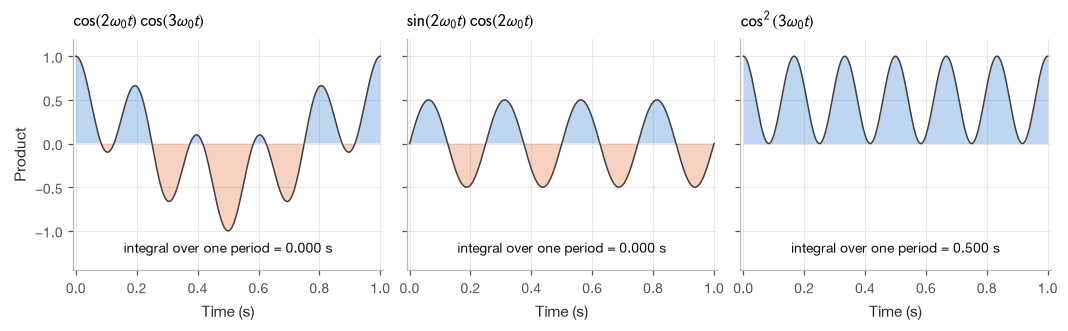

In [3]:
t = np.linspace(0, T, 1001)
products = [
    (np.cos(2 * w0 * t) * np.cos(3 * w0 * t), r"$\cos(2\omega_0 t)\,\cos(3\omega_0 t)$"),
    (np.sin(2 * w0 * t) * np.cos(2 * w0 * t), r"$\sin(2\omega_0 t)\,\cos(2\omega_0 t)$"),
    (np.cos(3 * w0 * t) ** 2, r"$\cos^2(3\omega_0 t)$"),
]

fig, axes = plt.subplots(1, 3, figsize=(9.6, 2.9), sharey=True)
for ax, (p, label) in zip(axes, products):
    ax.fill_between(t, p, 0, where=p >= 0, color=C[0], alpha=0.3, lw=0)
    ax.fill_between(t, p, 0, where=p < 0, color=C[1], alpha=0.3, lw=0)
    ax.plot(t, p, color="0.25", lw=1)
    area = round(np.trapezoid(p, t), 3) + 0.0       # + 0.0 turns -0.0 into 0.0
    ax.set(title=label, xlabel="Time (s)")
    ax.text(0.5, -1.25, f"integral over one period = {area:.3f} s", ha="center", fontsize=9)
axes[0].set(ylabel="Product", ylim=(-1.45, 1.2))
plt.show()

The numbers printed under each panel are the integrals over one period of length $T = 1$ s: zero, zero and $T/2 = 0.5$ s, exactly as [(5.3)](#eq-5-3) predicts. We can check all relations at once by building a matrix of normalized inner products $\frac{1}{T}\int_T \phi_i(t)\,\phi_j(t)\,dt$ between the first seven basis functions. Orthogonality means that this **Gram matrix** is diagonal.

In [4]:
t = np.linspace(0, T, 4001)
basis = {"1": np.ones_like(t)}
for n in (1, 2, 3):
    basis[f"cos{n}"] = np.cos(n * w0 * t)
    basis[f"sin{n}"] = np.sin(n * w0 * t)

names = list(basis)
gram = np.array([[np.trapezoid(basis[a] * basis[b], t) / T for b in names] for a in names])
print(pd.DataFrame(gram, index=names, columns=names).round(4) + 0.0)

        1  cos1  sin1  cos2  sin2  cos3  sin3
1     1.0   0.0   0.0   0.0   0.0   0.0   0.0
cos1  0.0   0.5   0.0   0.0   0.0   0.0   0.0
sin1  0.0   0.0   0.5   0.0   0.0   0.0   0.0
cos2  0.0   0.0   0.0   0.5   0.0   0.0   0.0
sin2  0.0   0.0   0.0   0.0   0.5   0.0   0.0
cos3  0.0   0.0   0.0   0.0   0.0   0.5   0.0
sin3  0.0   0.0   0.0   0.0   0.0   0.0   0.5


The diagonal holds 1 for the constant and $1/2$ for every sine and cosine, and every off-diagonal entry is zero to four decimals.

(sec-5-1-4)=
## 5.1.4 Finding the Coefficients

With orthogonality in hand, each coefficient falls out of a single integral. The idea is to multiply both sides of [(5.1)](#eq-5-1) by one particular basis function and integrate over a period. Every term in the series except one integrates to zero.

**Step 1: the DC term.** Integrate both sides of [(5.1)](#eq-5-1) over one period:

$$
\int_T x(t)\,dt = a_0\int_T dt + \sum_{n=1}^{\infty}\Big[a_n\underbrace{\int_T \cos(n\omega_0 t)\,dt}_{0} + b_n\underbrace{\int_T \sin(n\omega_0 t)\,dt}_{0}\Big] = a_0 T .
$$

We have exchanged the order of the infinite sum and the integral; for the signals in this book that step is justified, and [Section 5.3](03_convergence_gibbs.ipynb) states the conditions. Dividing by $T$,

(eq-5-4)=
\begin{equation*}
a_0 = \frac{1}{T}\int_T x(t)\,dt. \tag{5.4}
\end{equation*}

The DC coefficient is simply the average value of the signal over one period.

**Step 2: the cosine coefficients.** Fix an integer $m \ge 1$, multiply [(5.1)](#eq-5-1) by $\cos(m\omega_0 t)$ and integrate:

$$
\int_T x(t)\cos(m\omega_0 t)\,dt = a_0\int_T \cos(m\omega_0 t)\,dt + \sum_{n=1}^{\infty}\Big[a_n\int_T \cos(n\omega_0 t)\cos(m\omega_0 t)\,dt + b_n\int_T \sin(n\omega_0 t)\cos(m\omega_0 t)\,dt\Big].
$$

By [(5.2)](#eq-5-2) the first integral on the right is zero. By [(5.3)](#eq-5-3) every sine–cosine integral is zero and every cosine–cosine integral is zero except the single one with $n = m$, which equals $T/2$. The entire right-hand side collapses to $a_m T/2$, so after renaming $m$ back to $n$,

(eq-5-5)=
\begin{equation*}
a_n = \frac{2}{T}\int_T x(t)\cos(n\omega_0 t)\,dt, \qquad n \ge 1. \tag{5.5}
\end{equation*}

**Step 3: the sine coefficients.** Multiplying [(5.1)](#eq-5-1) by $\sin(m\omega_0 t)$ instead and repeating the argument leaves only $b_m T/2$ on the right:

(eq-5-6)=
\begin{equation*}
b_n = \frac{2}{T}\int_T x(t)\sin(n\omega_0 t)\,dt, \qquad n \ge 1. \tag{5.6}
\end{equation*}

Equations [(5.4)](#eq-5-4) to [(5.6)](#eq-5-6) have a simple reading, and it is the one I keep in mind whenever I compute a spectrum. To find how much of $\cos(n\omega_0 t)$ a signal contains, we correlate the signal with that cosine over one period. If the signal tends to be positive where the cosine is positive and negative where it is negative, the product is mostly positive and $a_n$ is large; if the two are unrelated, the product averages out. The factor $2/T$ undoes the $T/2$ that comes from the cosine's own "length squared" in [(5.3)](#eq-5-3). This is the projection of a vector onto an axis, carried out with integrals instead of dot products.

In code, each formula is one call to a numerical integrator. We use the trapezoidal rule on a fine grid covering exactly one period.

In [5]:
def fourier_coefficients(x, t, T, n_max):
    """Trigonometric Fourier coefficients a0, a_n, b_n (eqs. 7.4-7.6) by the trapezoidal rule."""
    w0 = 2 * np.pi / T
    n = np.arange(1, n_max + 1)[:, None]
    a0 = np.trapezoid(x, t) / T
    a = 2 / T * np.trapezoid(x * np.cos(n * w0 * t), t, axis=1)
    b = 2 / T * np.trapezoid(x * np.sin(n * w0 * t), t, axis=1)
    return a0, a, b


def partial_sum(a0, a, b, t, T, K):
    """Truncated Fourier series (7.1) with harmonics n = 1, ..., K."""
    w0 = 2 * np.pi / T
    n = np.arange(1, K + 1)[:, None]
    return a0 + (a[:K, None] * np.cos(n * w0 * t) + b[:K, None] * np.sin(n * w0 * t)).sum(axis=0)

(sec-5-1-5)=
## 5.1.5 Worked Examples: the Square Wave and the Sawtooth

**Example 5.1.1.** Find the Fourier series of the square wave of period $T$ that equals $+1$ for $0 < t < T/2$ and $-1$ for $T/2 < t < T$.

*The DC term.* Over one period the signal spends equal time at $+1$ and $-1$, so by [(5.4)](#eq-5-4) $a_0 = \frac{1}{T}\big(\tfrac{T}{2} - \tfrac{T}{2}\big) = 0$.

*The cosine terms.* Splitting the integral [(5.5)](#eq-5-5) at $T/2$, where the signal changes sign,

$$
\begin{aligned}
a_n &= \frac{2}{T}\left[\int_0^{T/2}\cos(n\omega_0 t)\,dt - \int_{T/2}^{T}\cos(n\omega_0 t)\,dt\right]\\[4pt]
&= \frac{2}{T}\cdot\frac{1}{n\omega_0}\Big[\big(\sin(n\pi) - \sin 0\big) - \big(\sin(2n\pi) - \sin(n\pi)\big)\Big] = 0,
\end{aligned}
$$

where we used $n\omega_0\,T/2 = n\pi$ and $n\omega_0 T = 2n\pi$, and the fact that the sine of any integer multiple of $\pi$ is zero. The square wave contains no cosines.

*The sine terms.* The same split in [(5.6)](#eq-5-6) gives

$$
\begin{aligned}
b_n &= \frac{2}{T}\left[\int_0^{T/2}\sin(n\omega_0 t)\,dt - \int_{T/2}^{T}\sin(n\omega_0 t)\,dt\right]\\[4pt]
&= \frac{2}{T}\cdot\frac{1}{n\omega_0}\Big[\big(-\cos(n\pi) + \cos 0\big) - \big(-\cos(2n\pi) + \cos(n\pi)\big)\Big]\\[4pt]
&= \frac{2}{T}\cdot\frac{T}{2\pi n}\Big[1 - (-1)^n + 1 - (-1)^n\Big]\\[4pt]
&= \frac{2\big(1 - (-1)^n\big)}{n\pi}.
\end{aligned}
$$

In the second line we used the antiderivative $-\cos(n\omega_0 t)/(n\omega_0)$; in the third, $\cos(n\pi) = (-1)^n$, $\cos(2n\pi) = 1$ and $1/(n\omega_0) = T/(2\pi n)$. The bracket $1 - (-1)^n$ equals 2 for odd $n$ and 0 for even $n$. Therefore

(eq-5-7)=
\begin{equation*}
b_n = \begin{cases}\dfrac{4}{n\pi}, & n \text{ odd},\\[6pt] 0, & n \text{ even},\end{cases}
\qquad\qquad
x(t) = \frac{4}{\pi}\left[\sin(\omega_0 t) + \frac{\sin(3\omega_0 t)}{3} + \frac{\sin(5\omega_0 t)}{5} + \cdots\right]. \tag{5.7}
\end{equation*}

These are the amplitudes used in the first figure of this section. A pleasant check: at $t = T/4$ the square wave equals 1, and $\sin(n\pi/2)$ alternates $1, -1, 1, \ldots$ over odd $n$, so [(5.7)](#eq-5-7) becomes $1 = \frac{4}{\pi}\left(1 - \frac{1}{3} + \frac{1}{5} - \cdots\right)$, which is Leibniz's famous series $\pi/4 = 1 - 1/3 + 1/5 - \cdots$.

**Example 5.1.2.** Find the Fourier series of the sawtooth wave that rises linearly as $x(t) = 2t/T$ for $-T/2 < t < T/2$ and repeats with period $T$.

Here it is convenient to integrate over the period $(-T/2, T/2)$. The function $2t/T$ is odd, and so is its product with any cosine, so the integrals [(5.4)](#eq-5-4) and [(5.5)](#eq-5-5) vanish: $a_0 = 0$ and $a_n = 0$. (We justify this kind of shortcut properly in the next subsection.) For the sine coefficients, the product $t\sin(n\omega_0 t)$ is even, so the integral over $(-T/2, T/2)$ is twice the integral over $(0, T/2)$:

$$
b_n = \frac{2}{T}\int_{-T/2}^{T/2}\frac{2t}{T}\sin(n\omega_0 t)\,dt = \frac{8}{T^2}\int_{0}^{T/2} t\,\sin(n\omega_0 t)\,dt .
$$

We integrate by parts with $u = t$ and $dv = \sin(n\omega_0 t)\,dt$, so $du = dt$ and $v = -\cos(n\omega_0 t)/(n\omega_0)$:

$$
\begin{aligned}
\int_{0}^{T/2} t\sin(n\omega_0 t)\,dt &= \left[-\frac{t\cos(n\omega_0 t)}{n\omega_0}\right]_0^{T/2} + \frac{1}{n\omega_0}\int_0^{T/2}\cos(n\omega_0 t)\,dt\\[4pt]
&= -\frac{T}{2}\cdot\frac{\cos(n\pi)}{n\omega_0} + \frac{\sin(n\pi)}{(n\omega_0)^2}
= -\frac{T}{2}\cdot\frac{(-1)^n}{n\omega_0}.
\end{aligned}
$$

Substituting back and using $n\omega_0 = 2\pi n/T$,

(eq-5-8)=
\begin{equation*}
b_n = \frac{8}{T^2}\cdot\left(-\frac{T}{2}\right)\frac{(-1)^n\,T}{2\pi n} = \frac{2(-1)^{n+1}}{n\pi},
\qquad
x(t) = \frac{2}{\pi}\left[\sin(\omega_0 t) - \frac{\sin(2\omega_0 t)}{2} + \frac{\sin(3\omega_0 t)}{3} - \cdots\right]. \tag{5.8}
\end{equation*}

Unlike the square wave, the sawtooth uses every harmonic, with alternating signs. In both cases the coefficients shrink only as $1/n$, slowly enough that many terms are needed. Both signals have jumps, and [Section 5.3](03_convergence_gibbs.ipynb) shows that this slow decay is the price of a discontinuity.

### Checking the formulas numerically

The next cell evaluates [(5.4)](#eq-5-4) to [(5.6)](#eq-5-6) by the trapezoidal rule on 4000 intervals per period and compares the results with [(5.7)](#eq-5-7) and [(5.8)](#eq-5-8). One detail matters at the jumps. We assign the signal its **midpoint value** there (0 for both waveforms), because the trapezoidal rule then gives exactly the average of the two one-sided rules on either side of the jump, which is the correct way to integrate a piecewise smooth function. Section 5.3 shows that the Fourier series itself also converges to this midpoint.

In [6]:
M = 4000                                         # trapezoidal intervals per period
t_sq = np.arange(M + 1) * T / M                  # one period, 0 <= t <= T
square = np.where(t_sq < T / 2, 1.0, -1.0)
square[np.isclose(t_sq % (T / 2), 0) | np.isclose(t_sq, T)] = 0.0    # midpoint at the jumps

t_saw = -T / 2 + np.arange(M + 1) * T / M        # one period, -T/2 <= t <= T/2
sawtooth = 2 * t_saw / T
sawtooth[[0, -1]] = 0.0                          # midpoint of the jump at t = +-T/2

n_max = 60
a0_sq, a_sq, b_sq = fourier_coefficients(square, t_sq, T, n_max)
a0_saw, a_saw, b_saw = fourier_coefficients(sawtooth, t_saw, T, n_max)

n = np.arange(1, n_max + 1)
b_sq_exact = np.where(n % 2 == 1, 4 / (n * np.pi), 0.0)        # eq. (7.7)
b_saw_exact = 2 * (-1.0) ** (n + 1) / (n * np.pi)              # eq. (7.8)

table = pd.DataFrame({"square b_n": b_sq[:7], "eq. (7.7)": b_sq_exact[:7],
                      "sawtooth b_n": b_saw[:7], "eq. (7.8)": b_saw_exact[:7]},
                     index=pd.Index(n[:7], name="n"))
print(table.round(5))
print(f"\nlargest |a0|, |a_n| (should be 0): {max(abs(a0_sq), abs(a_sq).max(), abs(a0_saw), abs(a_saw).max()):.1e}")
print(f"largest error in b_n, n <= {n_max}: square {abs(b_sq - b_sq_exact).max():.1e}, "
      f"sawtooth {abs(b_saw - b_saw_exact).max():.1e}")

   square b_n  eq. (7.7)  sawtooth b_n  eq. (7.8)
n                                                
1     1.27324    1.27324       0.63662    0.63662
2     0.00000    0.00000      -0.31831   -0.31831
3     0.42441    0.42441       0.21221    0.21221
4     0.00000    0.00000      -0.15915   -0.15915
5     0.25465    0.25465       0.12732    0.12732
6     0.00000    0.00000      -0.10610   -0.10610
7     0.18189    0.18189       0.09094    0.09095

largest |a0|, |a_n| (should be 0): 5.6e-16
largest error in b_n, n <= 60: square 1.5e-05, sawtooth 7.9e-06


The numerical and analytical coefficients agree to better than $10^{-4}$ for all 60 harmonics. The figure below shows partial sums, the series [(5.1)](#eq-5-1) truncated after $N$ harmonics, together with the coefficients. As $N$ grows, the partial sums hug the waveform more closely, but near each jump a small overshoot persists. That overshoot is the Gibbs phenomenon, the main subject of Section 5.3. I find it worth staring at the left column for a moment: the series converges, yet the worst-case error near the jump refuses to shrink.

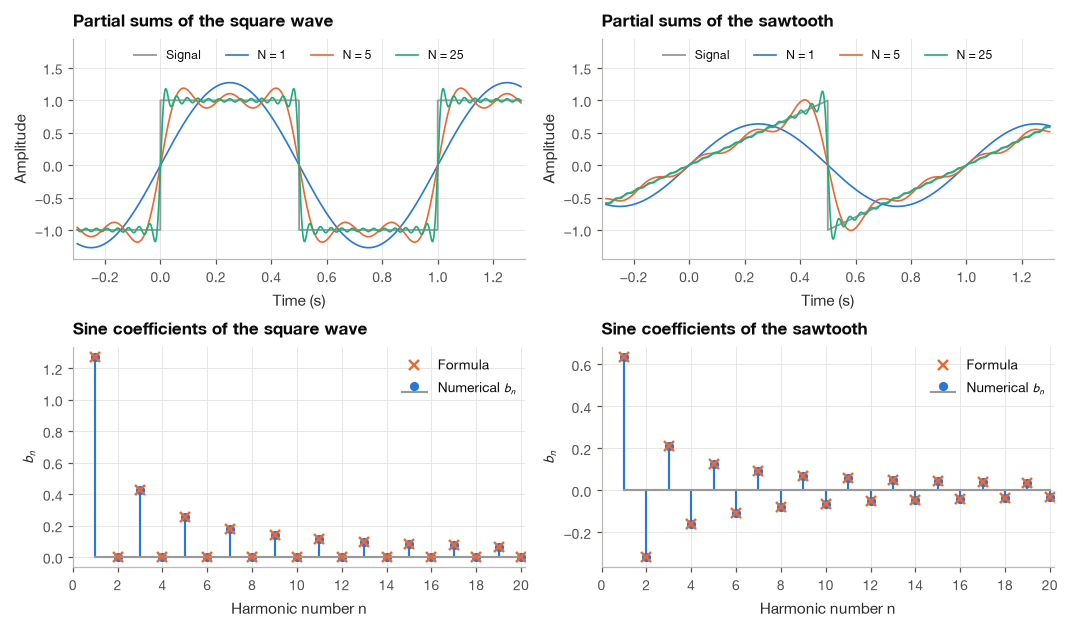

In [7]:
t_plot = np.linspace(-0.3, 1.3, 3201)
sq_plot = np.where((t_plot % T) < T / 2, 1.0, -1.0)
saw_plot = 2 * (((t_plot + T / 2) % T) - T / 2) / T

fig, axes = plt.subplots(2, 2, figsize=(9.6, 5.6))
for col, (wave, a0_, a_, b_, b_exact, name) in enumerate([
        (sq_plot, a0_sq, a_sq, b_sq, b_sq_exact, "square wave"),
        (saw_plot, a0_saw, a_saw, b_saw, b_saw_exact, "sawtooth")]):
    ax = axes[0, col]
    ax.plot(t_plot, wave, color="0.6", lw=1.2, label="Signal")
    for k, N in enumerate((1, 5, 25)):
        ax.plot(t_plot, partial_sum(a0_, a_, b_, t_plot, T, N), color=C[k], lw=1.1, label=f"N = {N}")
    ax.set(xlabel="Time (s)", ylabel="Amplitude", title=f"Partial sums of the {name}", ylim=(-1.45, 1.95))
    ax.legend(loc="upper center", ncols=4, fontsize=8)

    ax = axes[1, col]
    nn = np.arange(1, 21)
    ax.stem(nn, b_[:20], linefmt=C[0], markerfmt="o", basefmt="0.6", label="Numerical $b_n$")
    ax.plot(nn, b_exact[:20], "x", color=C[1], ms=7, mew=1.6, label="Formula")
    ax.set(xlabel="Harmonic number n", ylabel="$b_n$", title=f"Sine coefficients of the {name}")
    ax.set_xticks(np.arange(0, 21, 2))
    ax.legend(loc="upper right")
plt.show()

(sec-5-1-6)=
## 5.1.6 Symmetry Shortcuts

The integrals [(5.4)](#eq-5-4) to [(5.6)](#eq-5-6) are not always pleasant, and symmetry often tells us in advance that half of the coefficients are zero. Three kinds of symmetry matter in practice. In each case we integrate over the symmetric period $(-T/2, T/2)$ or split the period into halves.

### Even signals contain only cosines

A signal is **even** if $x(-t) = x(t)$, like a cosine or a pulse centered at $t = 0$. The product $x(t)\sin(n\omega_0 t)$ is then odd, because it is an even function times an odd one. The integral of an odd function over a symmetric interval is zero (the area on the left cancels the area on the right), so every $b_n$ vanishes. The product $x(t)\cos(n\omega_0 t)$ is even, so its integral over $(-T/2, T/2)$ is twice the integral over $(0, T/2)$:

$$
x \text{ even:}\qquad b_n = 0, \qquad a_n = \frac{4}{T}\int_0^{T/2}x(t)\cos(n\omega_0 t)\,dt .
$$

### Odd signals contain only sines

If $x(-t) = -x(t)$, as for the sawtooth, the roles swap: $x(t)\cos(n\omega_0 t)$ and $x(t)$ itself are odd, so $a_0 = 0$ and $a_n = 0$, and

$$
x \text{ odd:}\qquad a_0 = a_n = 0, \qquad b_n = \frac{4}{T}\int_0^{T/2}x(t)\sin(n\omega_0 t)\,dt .
$$

### Half-wave symmetry removes the even harmonics

A signal has **half-wave symmetry** if shifting it by half a period flips its sign, $x(t + T/2) = -x(t)$. The second half of each period is the first half upside down. The square wave has this property, and so does any sum of odd harmonics. To see what it implies, split the integral [(5.5)](#eq-5-5) into two halves and substitute $t = \tau + T/2$ in the second half:

$$
\begin{aligned}
a_n &= \frac{2}{T}\left[\int_0^{T/2}x(t)\cos(n\omega_0 t)\,dt + \int_{T/2}^{T}x(t)\cos(n\omega_0 t)\,dt\right]\\[4pt]
&= \frac{2}{T}\left[\int_0^{T/2}x(t)\cos(n\omega_0 t)\,dt + \int_{0}^{T/2}x(\tau + T/2)\cos(n\omega_0\tau + n\pi)\,d\tau\right].
\end{aligned}
$$

Two facts simplify the second integral. Half-wave symmetry gives $x(\tau + T/2) = -x(\tau)$, and shifting a cosine by $n\pi$ multiplies it by $(-1)^n$, so $\cos(n\omega_0\tau + n\pi) = (-1)^n\cos(n\omega_0\tau)$. The second integral is therefore $-(-1)^n$ times the first, and

(eq-5-9)=
\begin{equation*}
a_n = \frac{2}{T}\Big[1 - (-1)^n\Big]\int_0^{T/2}x(t)\cos(n\omega_0 t)\,dt = \begin{cases}\dfrac{4}{T}\displaystyle\int_0^{T/2}x(t)\cos(n\omega_0 t)\,dt, & n \text{ odd},\\[10pt] 0, & n \text{ even}.\end{cases} \tag{5.9}
\end{equation*}

The identical argument applies to $b_n$ (because $\sin(n\omega_0\tau + n\pi) = (-1)^n\sin(n\omega_0\tau)$ as well) and to $a_0$ (the two halves cancel). **A half-wave symmetric signal contains only odd harmonics.** The intuition is that every even harmonic completes a whole number of cycles in half a period, so it looks the same in both halves and cannot change sign between them as the signal does.

The square wave is odd *and* half-wave symmetric, which explains both features of [(5.7)](#eq-5-7): only sines, and only odd harmonics. The sawtooth is odd but not half-wave symmetric, so it has sines at every harmonic.

**Example 5.1.3.** The triangle wave $x(t) = 1 - 4|t|/T$ for $-T/2 \le t \le T/2$, repeated with period $T$, falls from $+1$ at $t = 0$ to $-1$ at $t = \pm T/2$. Find its Fourier series using symmetry.

The triangle is even, so $b_n = 0$. It is also half-wave symmetric: for $0 \le t \le T/2$, the value half a period later is $x(t - T/2) = 1 - 4(T/2 - t)/T = -1 + 4t/T = -x(t)$. Therefore only odd cosine harmonics survive. For odd $n$, using the even-signal formula,

$$
a_n = \frac{4}{T}\int_0^{T/2}\left(1 - \frac{4t}{T}\right)\cos(n\omega_0 t)\,dt
= \frac{4}{T}\underbrace{\int_0^{T/2}\cos(n\omega_0 t)\,dt}_{\sin(n\pi)/(n\omega_0)\, =\, 0} - \frac{16}{T^2}\int_0^{T/2} t\cos(n\omega_0 t)\,dt .
$$

Integration by parts with $u = t$, $dv = \cos(n\omega_0 t)\,dt$, $v = \sin(n\omega_0 t)/(n\omega_0)$ gives

$$
\int_0^{T/2} t\cos(n\omega_0 t)\,dt = \left[\frac{t\sin(n\omega_0 t)}{n\omega_0}\right]_0^{T/2} - \frac{1}{n\omega_0}\int_0^{T/2}\sin(n\omega_0 t)\,dt
= 0 + \frac{\cos(n\pi) - 1}{(n\omega_0)^2} = \frac{-2}{(n\omega_0)^2}\quad (n \text{ odd}).
$$

Substituting $(n\omega_0)^2 = 4\pi^2 n^2/T^2$,

(eq-5-10)=
\begin{equation*}
a_n = -\frac{16}{T^2}\cdot\frac{-2\,T^2}{4\pi^2 n^2} = \frac{8}{\pi^2 n^2}\ (n \text{ odd}),
\qquad
x(t) = \frac{8}{\pi^2}\left[\cos(\omega_0 t) + \frac{\cos(3\omega_0 t)}{9} + \frac{\cos(5\omega_0 t)}{25} + \cdots\right]. \tag{5.10}
\end{equation*}

The triangle has no jumps, only corners, and its coefficients fall as $1/n^2$, much faster than the $1/n$ of the square wave. We will see in Section 5.3 that this is no coincidence.

### Symmetry depends on where we put $t = 0$

Evenness and oddness are statements about the time origin, which is our choice, not a property of the physical signal. Delay the triangle by $T/8$ and it is neither even nor odd any more, so both $a_n$ and $b_n$ appear. Half-wave symmetry, on the other hand, survives any shift, because it compares the signal with itself half a period later. The next cell confirms both claims numerically and also computes $\sqrt{a_n^2 + b_n^2}$, which turns out not to change at all.

In [8]:
t1 = -T / 2 + np.arange(M + 1) * T / M
triangle = lambda tt: 1 - 4 * np.abs(((tt + T / 2) % T) - T / 2) / T

a0_tri, a_tri, b_tri = fourier_coefficients(triangle(t1), t1, T, 9)
a0_del, a_del, b_del = fourier_coefficients(triangle(t1 - T / 8), t1, T, 9)

n9 = np.arange(1, 10)
print(pd.DataFrame({"a_n": a_tri, "b_n": b_tri, "8/(pi n)^2": np.where(n9 % 2, 8 / (np.pi * n9) ** 2, 0),
                    "a_n delayed": a_del, "b_n delayed": b_del,
                    "sqrt(a^2+b^2) delayed": np.hypot(a_del, b_del)},
                   index=pd.Index(n9, name="n")).round(4) + 0.0)

      a_n  b_n  8/(pi n)^2  a_n delayed  b_n delayed  sqrt(a^2+b^2) delayed
n                                                                          
1  0.8106  0.0      0.8106       0.5732       0.5732                 0.8106
2  0.0000  0.0      0.0000       0.0000       0.0000                 0.0000
3  0.0901  0.0      0.0901      -0.0637       0.0637                 0.0901
4  0.0000  0.0      0.0000       0.0000       0.0000                 0.0000
5  0.0324  0.0      0.0324      -0.0229      -0.0229                 0.0324
6  0.0000  0.0      0.0000       0.0000       0.0000                 0.0000
7  0.0165  0.0      0.0165       0.0117      -0.0117                 0.0165
8  0.0000  0.0      0.0000       0.0000       0.0000                 0.0000
9  0.0100  0.0      0.0100       0.0071       0.0071                 0.0100


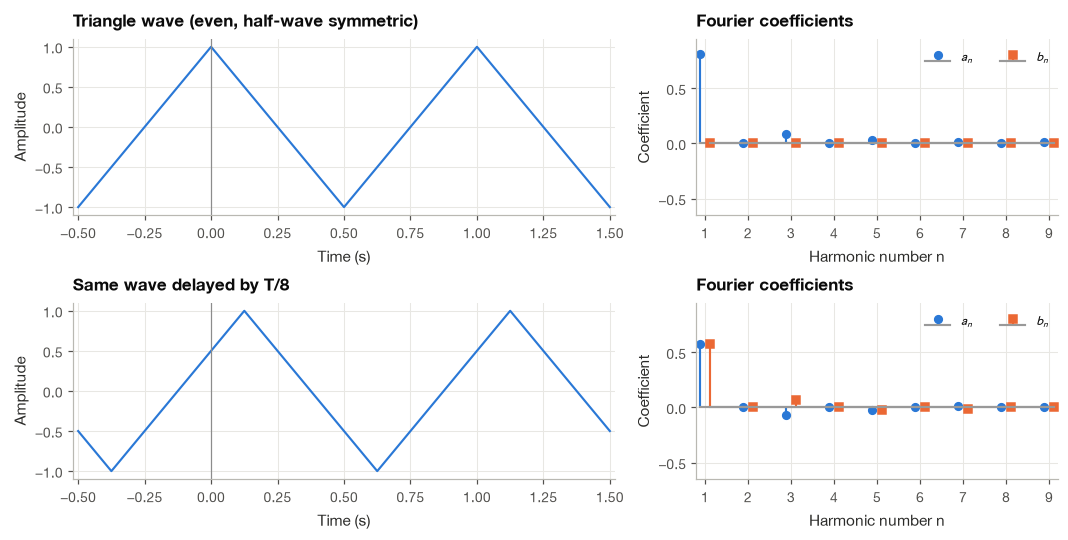

In [9]:
t_plot = np.linspace(-0.5, 1.5, 2001)
fig, axes = plt.subplots(2, 2, figsize=(9.6, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
for row, (shift, a_, b_, label) in enumerate([(0, a_tri, b_tri, "Triangle wave (even, half-wave symmetric)"),
                                               (T / 8, a_del, b_del, "Same wave delayed by T/8")]):
    ax = axes[row, 0]
    ax.plot(t_plot, triangle(t_plot - shift), color=C[0])
    ax.axvline(0, color="0.55", lw=0.8)
    ax.set(xlabel="Time (s)", ylabel="Amplitude", title=label)
    ax = axes[row, 1]
    ax.stem(n9 - 0.12, a_, linefmt=C[0], markerfmt="o", basefmt="0.6", label="$a_n$")
    ax.stem(n9 + 0.12, b_, linefmt=C[1], markerfmt="s", basefmt="0.6", label="$b_n$")
    ax.set(xlabel="Harmonic number n", ylabel="Coefficient", title="Fourier coefficients", ylim=(-0.65, 0.95))
    ax.set_xticks(n9)
    ax.legend(loc="upper right", ncols=2)
plt.show()

The undelayed triangle has only $a_n$, at odd $n$, with the values $8/(\pi n)^2$ of [(5.10)](#eq-5-10). The delayed copy has both $a_n$ and $b_n$, still only at odd $n$, and the combination $\sqrt{a_n^2 + b_n^2}$ is unchanged. The next subsection explains why.

(sec-5-1-7)=
## 5.1.7 The Amplitude–Phase Form

At each harmonic, the series [(5.1)](#eq-5-1) adds a cosine and a sine of the same frequency. Such a pair is always a single sinusoid with some amplitude and phase. To find them, expand a shifted cosine with the angle-addition formula:

$$
A_n\cos(n\omega_0 t + \varphi_n) = A_n\cos\varphi_n\,\cos(n\omega_0 t) - A_n\sin\varphi_n\,\sin(n\omega_0 t).
$$

This matches $a_n\cos(n\omega_0 t) + b_n\sin(n\omega_0 t)$ term by term if

$$
a_n = A_n\cos\varphi_n, \qquad b_n = -A_n\sin\varphi_n .
$$

Squaring and adding the two equations eliminates $\varphi_n$ (since $\cos^2 + \sin^2 = 1$), and dividing the second by the first eliminates $A_n$. The result is the **amplitude–phase form** of the Fourier series,

(eq-5-11)=
\begin{equation*}
x(t) = a_0 + \sum_{n=1}^{\infty}A_n\cos(n\omega_0 t + \varphi_n), \qquad A_n = \sqrt{a_n^2 + b_n^2}, \qquad \varphi_n = \operatorname{atan2}(-b_n,\ a_n). \tag{5.11}
\end{equation*}

As in [Section 2.1](../ch02_math_toolkit/01_complex_numbers.ipynb), the two-argument arctangent places the angle in the correct quadrant. The plot of $A_n$ against frequency $nf_0$ is the **amplitude spectrum** of the periodic signal, and the plot of $\varphi_n$ is its **phase spectrum**. They carry the same information as $(a_n, b_n)$ but in a form that is much easier to interpret: $A_n$ says how strong the $n$-th harmonic is, and $\varphi_n$ says where in the cycle it peaks.

Now the triangle experiment makes sense. Delaying a signal by $t_d$ replaces $t$ by $t - t_d$ in every term:

$$
A_n\cos\big(n\omega_0(t - t_d) + \varphi_n\big) = A_n\cos\big(n\omega_0 t + \varphi_n - n\omega_0 t_d\big).
$$

The amplitudes $A_n$ are untouched, and each phase decreases by $n\omega_0 t_d$, an amount proportional to the harmonic number. A delay rotates the phase of every harmonic in proportion to its frequency. This **linear phase** rule reappears for the Fourier transform in Section 8.3 and is the reason linear-phase filters preserve waveform shape ([Section 13.2](../ch13_filter_fundamentals/index.md)). For the delayed triangle, $t_d = T/8$ gives $n\omega_0 t_d = n\pi/4$, and the phases computed from the numerical coefficients follow this rule exactly.

In [10]:
odd = n9 % 2 == 1
phi_del = np.arctan2(-b_del, a_del)                  # eq. (7.11)
print("n                    :", n9[odd])
print("phase, delayed (rad) :", phi_del[odd])
print("-n*pi/4, wrapped     :", np.angle(np.exp(-1j * n9[odd] * np.pi / 4)))

n                    : [1 3 5 7 9]
phase, delayed (rad) : [-0.7854 -2.3562  2.3562  0.7854 -0.7854]
-n*pi/4, wrapped     : [-0.7854 -2.3562  2.3562  0.7854 -0.7854]


(sec-5-1-8)=
## 5.1.8 Application: the Flow Waveform of a Mechanical Ventilator

In volume-controlled mechanical ventilation the ventilator delivers air at a constant flow for a fixed inspiratory time, then opens the expiratory valve and lets the lungs empty passively. The resulting flow waveform is periodic, with a rectangular inspiratory phase followed by an exponentially decaying expiratory phase. I chose it as the first application because it has no even or odd symmetry, no half-wave symmetry and two sharp corners per breath, so none of the shortcuts of [Section 5.1.6](#sec-5-1-6) apply and the coefficient formulas have to do all the work.

### Step 1: Build one period of the waveform

We use parameters typical of an adult patient on a ventilator: a respiratory rate of 15 breaths/min, so $T = 4$ s and $f_0 = 0.25$ Hz; a tidal volume of 0.5 L delivered at 0.5 L/s over $T_i = 1$ s (an inspiratory-to-expiratory ratio of 1:3); and passive expiration with the time constant $\tau = RC = 0.5$ s that results from an airway resistance of $R = 10\ \text{cmH}_2\text{O}\cdot\text{s/L}$ and a respiratory compliance of $C = 0.05\ \text{L/cmH}_2\text{O}$. During expiration the flow is $-\frac{V}{\tau(1 - e^{-T_e/\tau})}e^{-(t - T_i)/\tau}$, where $T_e = T - T_i$ is the expiratory time and the denominator scales the exponential so that exactly the inspired volume $V$ leaves the lungs by the end of the cycle. As before, we sample one period finely and give the samples at the two jumps their midpoint values.

In [11]:
T_vent, Ti, V_tidal, tau = 4.0, 1.0, 0.5, 0.5        # s, s, L, s
Te = T_vent - Ti
peak_exp = V_tidal / (tau * (1 - np.exp(-Te / tau)))  # L/s, so that exhaled volume = V_tidal


def vent_flow(tt):
    """Volume-controlled ventilator flow (L/s): square inspiration, passive exponential expiration."""
    tc = tt % T_vent
    return np.where(tc < Ti, V_tidal / Ti, -peak_exp * np.exp(-(tc - Ti) / tau))


M_v = 20000
t_v = np.arange(M_v + 1) * T_vent / M_v
flow = vent_flow(t_v)
flow[np.isclose(t_v, Ti)] = 0.5 * (V_tidal / Ti - peak_exp)       # midpoint at the jumps
flow[[0, -1]] = 0.5 * (V_tidal / Ti - peak_exp * np.exp(-Te / tau))
print(f"inspiratory flow {V_tidal / Ti:.2f} L/s, peak expiratory flow {-peak_exp:.3f} L/s")
print(f"net volume over one breath: {np.trapezoid(flow, t_v):.1e} L")

inspiratory flow 0.50 L/s, peak expiratory flow -1.002 L/s
net volume over one breath: -6.7e-09 L


### Step 2: Compute the coefficients and the amplitude–phase spectrum

The function `fourier_coefficients` from [Section 5.1.4](#sec-5-1-4) evaluates [(5.4)](#eq-5-4) to [(5.6)](#eq-5-6), and [(5.11)](#eq-5-11) converts the result to amplitudes and phases.

In [12]:
a0_v, a_v, b_v = fourier_coefficients(flow, t_v, T_vent, 200)
A_v = np.hypot(a_v, b_v)
phi_v = np.arctan2(-b_v, a_v)

print(f"DC component a0   : {a0_v:.2e} L/s")
print(f"A_1 ... A_8 (L/s) : {A_v[:8]}")
print(f"phi_1 ... phi_4   : {phi_v[:4]} rad")

DC component a0   : -1.67e-09 L/s
A_1 ... A_8 (L/s) : [0.2813 0.2824 0.1699 0.0758 0.0933 0.1046 0.0736 0.0393]
phi_1 ... phi_4   : [-0.0158 -1.3113 -2.5725  1.879 ] rad


The DC coefficient is zero to within numerical precision, which is the Fourier-series statement of a physical fact: in steady state the lungs exhale exactly what they inhale, so the mean flow over a breath is zero.

### Step 3: Reconstruct with K harmonics and measure the error

To judge how many harmonics the waveform needs, we compare partial sums with the original and report the RMS of the difference relative to the RMS of the flow itself.

In [13]:
rms = np.sqrt(np.trapezoid(flow ** 2, t_v) / T_vent)
for K in (3, 10, 40):
    err = flow - partial_sum(a0_v, a_v, b_v, t_v, T_vent, K)
    rel = np.sqrt(np.trapezoid(err ** 2, t_v) / T_vent) / rms
    print(f"K = {K:3d} harmonics (up to {K / T_vent:5.2f} Hz): relative RMS error {100 * rel:5.1f} %")

K =   3 harmonics (up to  0.75 Hz): relative RMS error  50.1 %
K =  10 harmonics (up to  2.50 Hz): relative RMS error  30.6 %
K =  40 harmonics (up to 10.00 Hz): relative RMS error  15.8 %


The numbers are less comfortable than one might expect for such a simple-looking waveform. With three harmonics the partial sum captures only the broad push and pull of the breath, with a relative RMS error of 50%. Ten harmonics (up to 2.5 Hz) still leave about 31% error, and even forty harmonics (up to 10 Hz) leave about 16%.

### Step 4: Plot the partial sums and the spectrum

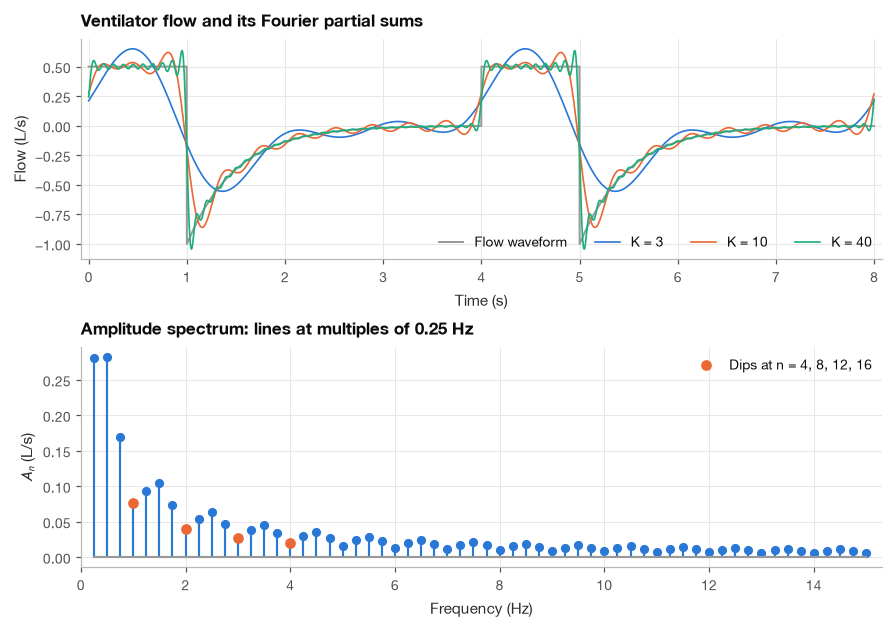

In [14]:
t_plot = np.linspace(0, 2 * T_vent, 4001)[:-1]
fig, axes = plt.subplots(2, 1, figsize=(8, 5.6))
ax = axes[0]
ax.plot(t_plot, vent_flow(t_plot), color="0.6", lw=1.3, label="Flow waveform")
for k, K in enumerate((3, 10, 40)):
    ax.plot(t_plot, partial_sum(a0_v, a_v, b_v, t_plot, T_vent, K), color=C[k], lw=1.1, label=f"K = {K}")
ax.set(xlabel="Time (s)", ylabel="Flow (L/s)", title="Ventilator flow and its Fourier partial sums")
ax.legend(loc="lower right", ncols=4)

ax = axes[1]
f_harm = np.arange(1, 61) / T_vent
ax.stem(f_harm, A_v[:60], linefmt=C[0], markerfmt="o", basefmt="0.6")
dips = np.array([4, 8, 12, 16])
ax.plot(dips / T_vent, A_v[dips - 1], "o", color=C[1], ms=6, label="Dips at n = 4, 8, 12, 16")
ax.legend(loc="upper right")
ax.set(xlabel="Frequency (Hz)", ylabel="$A_n$ (L/s)", title="Amplitude spectrum: lines at multiples of 0.25 Hz",
       xlim=(0, 15.3))
plt.show()

### Step 5: Read the spectrum

The top panel shows where the error of Step 3 lives: almost entirely at the instants when the valves open and close, where the partial sums ring and overshoot. Between the corners even ten harmonics follow the waveform well. Three features of the amplitude spectrum in the bottom panel explain this behavior. First, it is a **line spectrum**: energy exists only at multiples of the 0.25 Hz breathing rate, as [(5.1)](#eq-5-1) requires. Second, the envelope decays roughly as $1/n$, the signature of the jumps in the waveform, which is why so many harmonics are needed. Third, the amplitudes dip at $n = 4, 8, 12, \ldots$. The inspiratory plateau lasts exactly one quarter of the cycle, so the fourth harmonic completes one full oscillation during inspiration and its correlation with the flat plateau is zero; only the expiratory part contributes at those harmonics. [Section 5.2](02_complex_fourier_series.ipynb) shows that a rectangular pulse occupying a fraction $T_i/T$ of the period always produces such dips at multiples of $T/T_i$.

```{note}
The same reasoning applies to any sensor that records the flow. A pneumotachograph or flow sensor that passes only the first few hertz rounds off the corners of a square inspiratory flow, and a display built from it will show a smoother waveform than the one the patient receives. Knowing the harmonic content of a signal tells us how much bandwidth the measurement chain needs, and the same question for the ECG (how much bandwidth does a QRS complex need?) runs through the rest of this chapter.
```

## Summary

A periodic signal with period $T$ can be written as a constant plus a sum of cosines and sines at the harmonic frequencies $n\omega_0 = 2\pi n/T$, equation [(5.1)](#eq-5-1). The coefficients follow from the orthogonality relations [(5.3)](#eq-5-3): multiplying the series by one basis function and integrating over a period kills every term but one, which gives $a_0$ as the mean value [(5.4)](#eq-5-4) and $a_n$, $b_n$ as correlations with the corresponding cosine and sine (7.5, 7.6). The square wave and the sawtooth have coefficients $4/(n\pi)$ at odd $n$ and $2(-1)^{n+1}/(n\pi)$, and trapezoidal integration over one sampled period reproduces them closely. Even signals contain only cosines, odd signals only sines, and half-wave symmetric signals only odd harmonics; the first two depend on the choice of time origin, the third does not. Combining each cosine–sine pair into $A_n\cos(n\omega_0 t + \varphi_n)$ gives the amplitude and phase spectra, in which a time delay appears as a phase shift proportional to frequency.

The next section rewrites the series with complex exponentials, which turns the three coefficient formulas into one and leads to Parseval's theorem. [Section 5.3](03_convergence_gibbs.ipynb) then asks what happens at the jumps of the square wave and the ventilator waveform, and Section 7.4 applies the series to real ECG and PPG cycles.

## Exercises

1. Use Euler's formula $\cos\theta = (e^{j\theta} + e^{-j\theta})/2$ instead of the product-to-sum identities to prove that $\int_T\cos(m\omega_0 t)\cos(n\omega_0 t)\,dt = 0$ for $m \neq n$. Which step of your proof uses the fact that $m$ and $n$ are integers?
2. Show that a signal that is both even and half-wave symmetric has $a_n = \frac{8}{T}\int_0^{T/4}x(t)\cos(n\omega_0 t)\,dt$ for odd $n$, so that only a quarter of the period is needed. Recompute the triangle coefficients [(5.10)](#eq-5-10) this way.
3. The full-wave rectified sinusoid $x(t) = |\sin(2\pi t/T_1)|$ is the output of a bridge rectifier. What is its fundamental period? Derive its Fourier series by hand, state which symmetry properties you used, and check the first five coefficients with `fourier_coefficients`.
4. Shift the square wave of Example 5.1.1 so that it becomes even (centered on $t = 0$). Predict its coefficients from [(5.7)](#eq-5-7) using the amplitude–phase form and the delay rule of [Section 5.1.7](#sec-5-1-7), then verify numerically.
5. Repeat the ventilator example with an inspiratory-to-expiratory ratio of 1:2 at the same tidal volume and respiratory rate. Where do the dips in the amplitude spectrum move, and how many harmonics are now needed for a relative RMS error below 20%? Explain the change.
6. Load the first 10 s of lead MLII of MIT-BIH record 100 (`wfdb.rdrecord("../data/mitdb/100", sampto=3600)`), cut out one RR interval that starts 0.3 s before an annotated R peak, and treat it as one period. Compute $a_0$, $a_n$ and $b_n$ for $n \le 40$ with `fourier_coefficients`, convert them to $A_n$ with [(5.11)](#eq-5-11) and plot $A_n$ against frequency in hertz. Above which frequency do the amplitudes stay below 1% of the largest one? Compare the decay with the ventilator spectrum, and keep your code: Section 7.4 takes this experiment much further.

## Further Reading

Fourier's own treatise {cite:p}`fourier1822` is still readable and shows how the series arose from a physical problem. {cite:t}`oppenheim1997` (Chapter 3) and {cite:t}`lathi2018` (Chapter 6) develop the trigonometric and exponential series in the same spirit as this section, with many further worked examples. {cite:t}`bracewell2000` gives a physically minded treatment of Fourier series and transforms with a wealth of pictures, and {cite:t}`semmlow2014` discusses the Fourier series of biomedical waveforms with MATLAB examples.